# Phase 2: Exploratory Data Analysis (EDA)

In this phase, we will explore the cleaned datasets to understand customer behaviour, sales performance, product performance, payment trends, returns, and inventory patterns. Identify meaningful business insights that can support data-driven decisions.

In [1]:
import pandas as pd
from pathlib import Path

cleaned_path = Path("../data/cleaned")

customers = pd.read_csv(cleaned_path / "customers.csv")
inventory = pd.read_csv(cleaned_path / "inventory.csv")
order_items = pd.read_csv(cleaned_path / "order_items.csv")
orders = pd.read_csv(cleaned_path / "orders.csv")
payments = pd.read_csv(cleaned_path / "payments.csv")
products = pd.read_csv(cleaned_path / "products.csv")
returns = pd.read_csv(cleaned_path / "returns.csv")
suppliers = pd.read_csv(cleaned_path / "suppliers.csv")

print("All eight cleaned datasets loaded successfully.")

All eight cleaned datasets loaded successfully.


In [2]:
datasets = {
    "customers": customers,
    "inventory": inventory,
    "order_items": order_items,
    "orders": orders,
    "payments": payments,
    "products": products,
    "returns": returns,
    "suppliers": suppliers
}

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]} rows, {df.shape[1]} columns")

print(f"\nTotal rows across all datasets: {sum(df.shape[0] for df in datasets.values()):,}")

customers: 10000 rows, 17 columns
inventory: 1000 rows, 11 columns
order_items: 100000 rows, 11 columns
orders: 50000 rows, 19 columns
payments: 50000 rows, 13 columns
products: 1000 rows, 17 columns
returns: 10000 rows, 10 columns
suppliers: 200 rows, 14 columns

Total rows across all datasets: 222,200


The PRD reportedly estimates approximately 216,200 rows, so your actual datasets contain 6,000 more rows than that estimate. We should document this discrepancy rather than alter any data to force the totals to match.

Next, we'll identify missing values in each dataset. This helps us decide which columns need attention during EDA.

In [3]:
for name, df in datasets.items():
    missing = df.isnull().sum()
    missing = missing[missing > 0].sort_values(ascending=False)

    print(f"\n{name}")
    if missing.empty:
        print("No missing values")
    else:
        print(missing)


customers
No missing values

inventory
No missing values

order_items
No missing values

orders
delivered_date    17501
dtype: int64

payments
refund_date    50000
dtype: int64

products
No missing values

returns
No missing values

suppliers
No missing values


Now let's quantify the missing values % so we can compare their scale across datasets.

In [4]:
for name, df in datasets.items():
    missing_count = df.isnull().sum().sum()
    total_cells = df.size
    missing_percentage = (missing_count / total_cells) * 100

    print(f"{name}: {missing_count} missing values ({missing_percentage:.2f}% of cells)")

customers: 0 missing values (0.00% of cells)
inventory: 0 missing values (0.00% of cells)
order_items: 0 missing values (0.00% of cells)
orders: 17501 missing values (1.84% of cells)
payments: 50000 missing values (7.69% of cells)
products: 0 missing values (0.00% of cells)
returns: 0 missing values (0.00% of cells)
suppliers: 0 missing values (0.00% of cells)


The results confirm that missing values occur only in orders and payments. The next step is to check whether these missing values correspond to particular business statuses.

In [5]:
print("Order status vs. missing delivery date:")
print(pd.crosstab(orders["status"], orders["delivered_date"].isnull(), margins=True))

print("\nPayment status vs. missing refund date:")
print(pd.crosstab(payments["status"], payments["refund_date"].isnull(), margins=True))

Order status vs. missing delivery date:


delivered_date  False   True    All
status                             
Cancelled           0   5996   5996
Delivered       32499      0  32499
Processing          0   2501   2501
Returned            0   3933   3933
Shipped             0   5071   5071
All             32499  17501  50000

Payment status vs. missing refund date:
refund_date   True    All
status                   
Failed        1748   1748
Success      48252  48252
All          50000  50000


- Orders: All 32,499 Delivered orders have delivery dates. The remaining 17,501 orders have missing delivery dates, matching their non-delivered statuses.
- Payments: All 50,000 payment records have missing refund_date values, including all 1,748 Failed payments and 48,252 Success payments.

The missing refund dates are worth documenting, but we shouldn't assume they are errors just because they're missing.

Next, let's understand the distribution of orders across different statuses. This will help us assess how many orders were delivered, cancelled, returned, shipped, or are still processing.

In [6]:
status_counts = orders["status"].value_counts()

print(status_counts)
print(f"\nTotal orders: {status_counts.sum():,}")

status
Delivered     32499
Cancelled      5996
Shipped        5071
Returned       3933
Processing     2501
Name: count, dtype: int64

Total orders: 50,000


We can now calculate the percentage represented by each status, which will make the findings easier to compare and later present in your dashboard.

In [7]:
status_summary = orders["status"].value_counts().to_frame(name="order_count")
status_summary["percentage"] = (status_summary["order_count"] / len(orders)) * 100

print(status_summary.round(2))

            order_count  percentage
status                             
Delivered         32499       65.00
Cancelled          5996       11.99
Shipped            5071       10.14
Returned           3933        7.87
Processing         2501        5.00

- 65.00% of orders are Delivered.
- 11.99% are Cancelled.
- 10.14% are Shipped.
- 7.87% are Returned.
- 5.00% are Processing.

We'll not interpret the non-delivered statuses as failed deliveries because Shipped and Processing orders may still be in progress.

Now let's create a donut chart to make the status distribution easier to understand

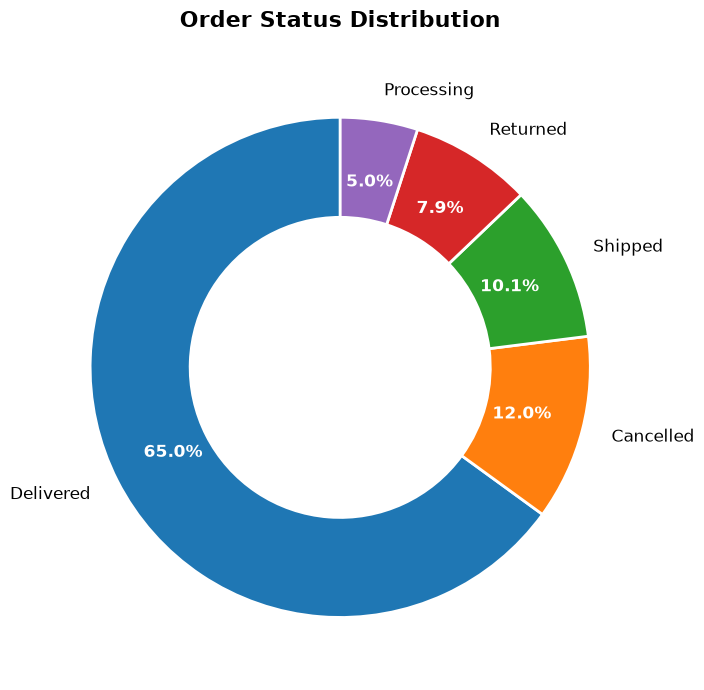

In [8]:
import matplotlib.pyplot as plt
from pathlib import Path

status_counts = orders["status"].value_counts()

plt.figure(figsize=(9, 7))

plt.pie(
    status_counts,
    labels=status_counts.index,
    autopct="%1.1f%%",
    pctdistance=0.75,
    labeldistance=1.12,
    startangle=90,
    textprops={"fontsize": 12},
    wedgeprops={"width": 0.4, "edgecolor": "white", "linewidth": 2}
)

for text in plt.gca().texts:
    if "%" in text.get_text():
        text.set_color("white")
        text.set_fontweight("bold")
        text.set_fontsize(12)

plt.title("Order Status Distribution", fontsize=16, fontweight="bold", pad=20)
plt.tight_layout()

chart_path = Path("../outputs/charts")
chart_path.mkdir(parents=True, exist_ok=True)

plt.savefig(
    chart_path / "chart_04_order_status_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Observations — Order Status Distribution**

1. Delivered orders account for 65.00% of all 50,000 orders, making this the largest order-status category.
2. Cancelled orders represent 11.99%, while Returned orders account for 7.87% of all orders.
3. Shipped and Processing orders together represent 15.14% of orders, indicating that these orders are not recorded as Delivered, Cancelled, or Returned.

### Next: Monthly Order Volume

First, let's verify the date range.

In [9]:
print("Earliest order date:", orders["order_date"].min())
print("Latest order date:", orders["order_date"].max())

Earliest order date: 2023-06-24
Latest order date: 2025-06-23


We'll group orders by calendar month, count them, and highlight October and November to make the Diwali-period pattern easier to see.

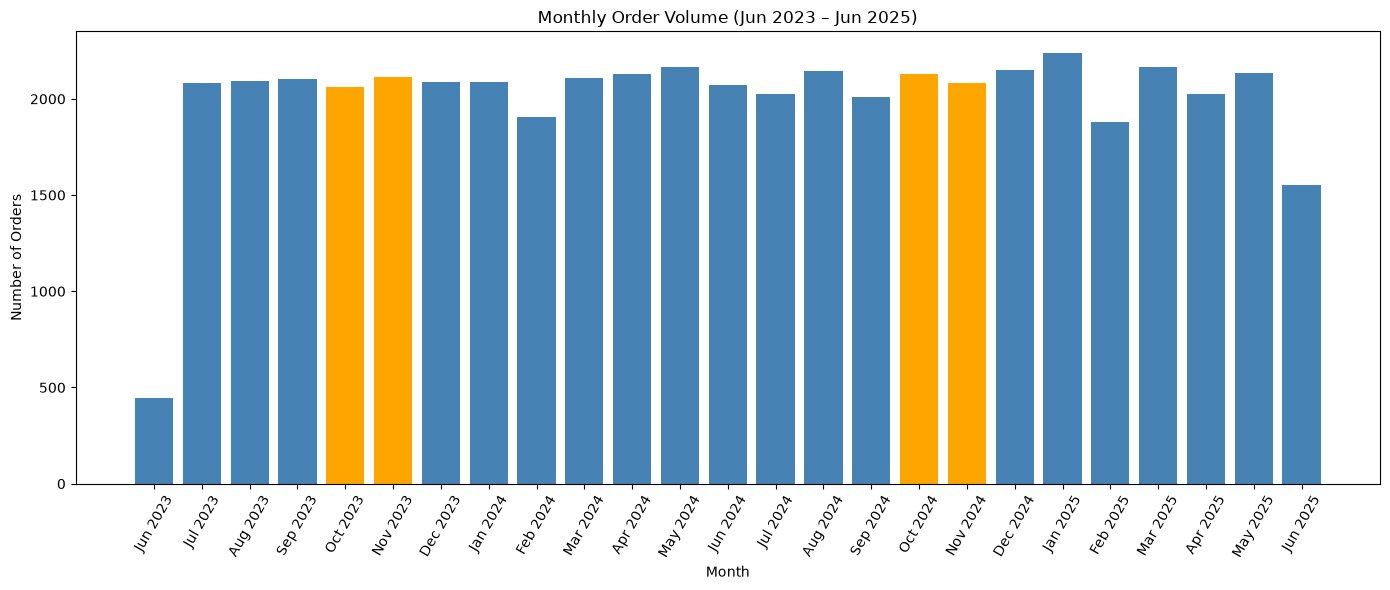

In [10]:
orders["order_date"] = pd.to_datetime(orders["order_date"])

monthly_orders = (
    orders.set_index("order_date")
    .resample("MS")
    .size()
)

plt.figure(figsize=(14, 6))

bar_colors = [
    "orange" if date.month in [10, 11] else "steelblue"
    for date in monthly_orders.index
]

plt.bar(
    monthly_orders.index.strftime("%b %Y"),
    monthly_orders.values,
    color=bar_colors
)

plt.title("Monthly Order Volume (Jun 2023 – Jun 2025)")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=60)
plt.tight_layout()

plt.savefig(
    chart_path / "chart_01_monthly_order_volume.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Observations — Monthly Order Volume**

1. Monthly order volume is generally around 2,000–2,250 orders during most full months, with some fluctuations throughout the period.
2. October and November are highlighted to examine the Diwali period. The chart shows elevated order volume in November 2023 and October 2024, but the pattern does not establish that Diwali caused the increases.
3. June 2023 and June 2025 have lower counts because the dataset covers only part of each month; these months should not be compared directly with complete months.

### NEXT- Monthly Revenue (GMV)

we'll use final_amount to calculate monthly revenue and compare the same months across years.

In [11]:
monthly_revenue = (
    orders.set_index("order_date")
    .resample("MS")["final_amount"]
    .sum()
)

print(monthly_revenue)

order_date
2023-06-01    2.738485e+07
2023-07-01    1.289205e+08
2023-08-01    1.281220e+08
2023-09-01    1.374625e+08
2023-10-01    1.324709e+08
2023-11-01    1.372634e+08
2023-12-01    1.369234e+08
2024-01-01    1.314500e+08
2024-02-01    1.209459e+08
2024-03-01    1.336701e+08
2024-04-01    1.315097e+08
2024-05-01    1.363584e+08
2024-06-01    1.237410e+08
2024-07-01    1.270283e+08
2024-08-01    1.319235e+08
2024-09-01    1.305253e+08
2024-10-01    1.335183e+08
2024-11-01    1.262641e+08
2024-12-01    1.330895e+08
2025-01-01    1.379291e+08
2025-02-01    1.141167e+08
2025-03-01    1.364932e+08
2025-04-01    1.308222e+08
2025-05-01    1.358494e+08
2025-06-01    1.036033e+08
Freq: MS, Name: final_amount, dtype: float64


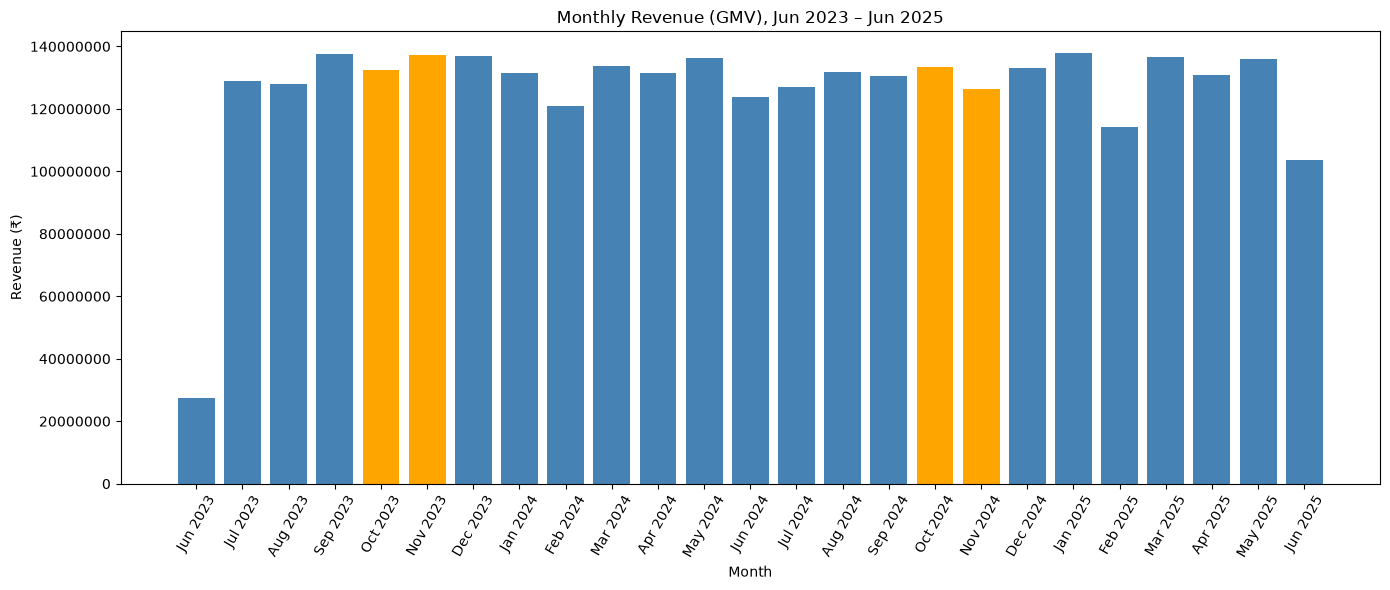

In [12]:
plt.figure(figsize=(14, 6))

bar_colors = [
    "orange" if date.month in [10, 11] else "steelblue"
    for date in monthly_revenue.index
]

plt.bar(
    monthly_revenue.index.strftime("%b %Y"),
    monthly_revenue.values,
    color=bar_colors
)

plt.title("Monthly Revenue (GMV), Jun 2023 – Jun 2025")
plt.xlabel("Month")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=60)
plt.ticklabel_format(axis="y", style="plain")
plt.tight_layout()

plt.savefig(
    chart_path / "chart_02_monthly_revenue_gmv.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

LET'S COMPARE ALL ELIGIBLE MONTHLY REVENUE YEAR OVER YEAR

In [15]:
revenue_by_year = monthly_revenue.to_frame(name="revenue")
revenue_by_year["year"] = revenue_by_year.index.year
revenue_by_year["month"] = revenue_by_year.index.month

revenue_comparison = revenue_by_year.pivot(
    index="month",
    columns="year",
    values="revenue"
)

revenue_comparison["2024 vs 2023 (%)"] = (
    (revenue_comparison[2024] - revenue_comparison[2023])
    / revenue_comparison[2023] * 100
).round(2)

revenue_comparison["2025 vs 2024 (%)"] = (
    (revenue_comparison[2025] - revenue_comparison[2024])
    / revenue_comparison[2024] * 100
).round(2)

revenue_comparison.index = revenue_comparison.index.map(
    lambda month: pd.Timestamp(2000, month, 1).strftime("%B")
)

print("2024 vs 2023 — July to December:")
print(revenue_comparison.loc[
    ["July", "August", "September", "October", "November", "December"],
    [2023, 2024, "2024 vs 2023 (%)"]
])

print("\n2025 vs 2024 — January to May:")
print(revenue_comparison.loc[
    ["January", "February", "March", "April", "May"],
    [2024, 2025, "2025 vs 2024 (%)"]
])

2024 vs 2023 — July to December:
year               2023          2024  2024 vs 2023 (%)
month                                                  
July       1.289205e+08  1.270283e+08             -1.47
August     1.281220e+08  1.319235e+08              2.97
September  1.374625e+08  1.305253e+08             -5.05
October    1.324709e+08  1.335183e+08              0.79
November   1.372634e+08  1.262641e+08             -8.01
December   1.369234e+08  1.330895e+08             -2.80

2025 vs 2024 — January to May:
year              2024          2025  2025 vs 2024 (%)
month                                                 
January   1.314500e+08  1.379291e+08              4.93
February  1.209459e+08  1.141167e+08             -5.65
March     1.336701e+08  1.364932e+08              2.11
April     1.315097e+08  1.308222e+08             -0.52
May       1.363584e+08  1.358494e+08             -0.37


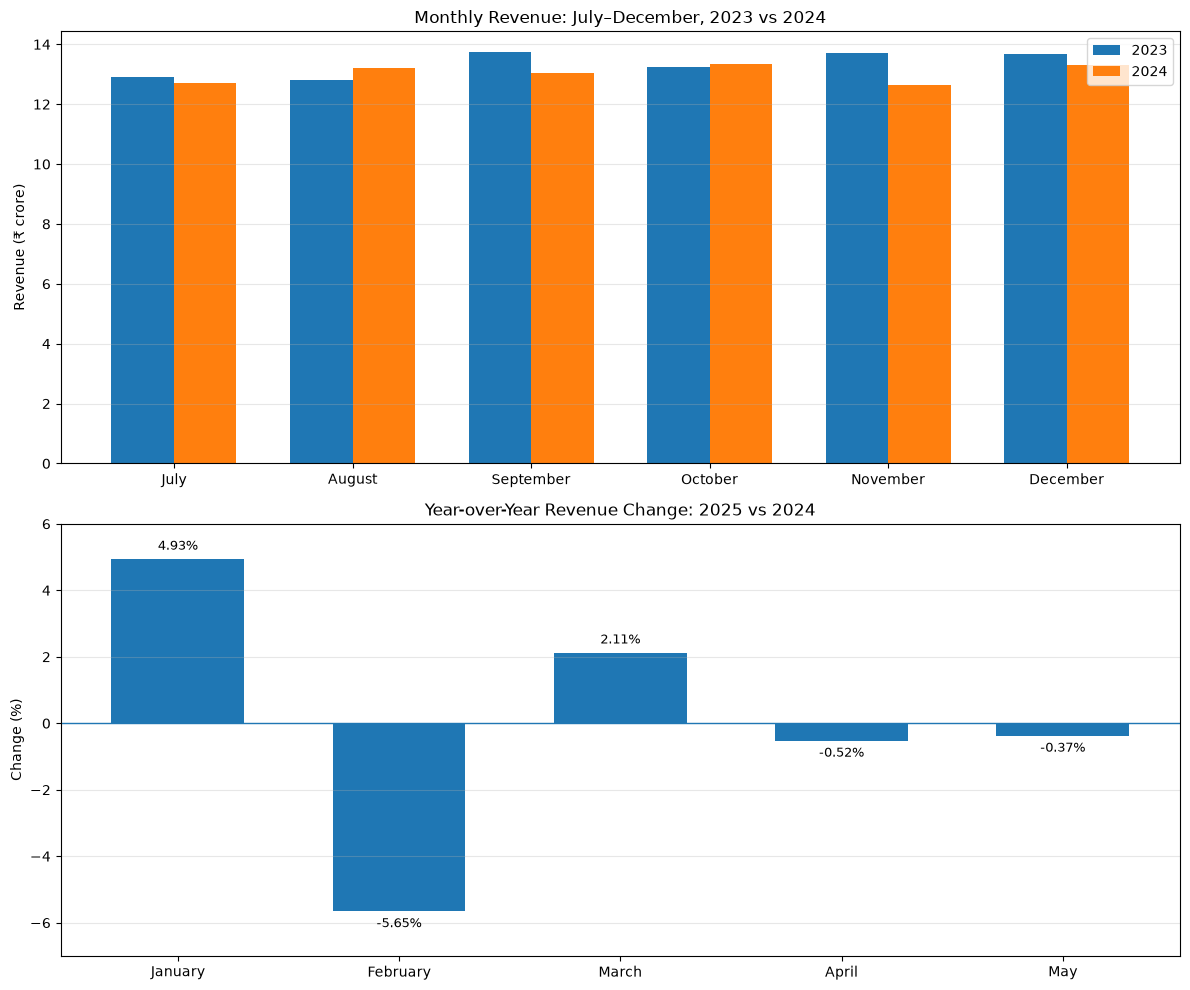

In [18]:
import matplotlib.pyplot as plt
import numpy as np

comparison_2024 = revenue_comparison.loc[
    ["July", "August", "September", "October", "November", "December"],
    [2023, 2024]
]

comparison_2025 = revenue_comparison.loc[
    ["January", "February", "March", "April", "May"],
    [2024, 2025]
]

fig, axes = plt.subplots(2, 1, figsize=(12, 10))

x1 = np.arange(len(comparison_2024))
width = 0.35

axes[0].bar(x1 - width / 2, comparison_2024[2023] / 1e7, width, label="2023")
axes[0].bar(x1 + width / 2, comparison_2024[2024] / 1e7, width, label="2024")
axes[0].set_xticks(x1)
axes[0].set_xticklabels(comparison_2024.index)
axes[0].set_title("Monthly Revenue: July–December, 2023 vs 2024")
axes[0].set_ylabel("Revenue (₹ crore)")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

x2 = np.arange(len(comparison_2025))
changes = revenue_comparison.loc[
    ["January", "February", "March", "April", "May"],
    "2025 vs 2024 (%)"
]

axes[1].bar(x2, changes, width=0.6)
axes[1].axhline(0, linewidth=1)
axes[1].set_xticks(x2)
axes[1].set_xticklabels(comparison_2025.index)
axes[1].set_title("Year-over-Year Revenue Change: 2025 vs 2024")
axes[1].set_ylabel("Change (%)")
axes[1].grid(axis="y", alpha=0.3)

for i, value in enumerate(changes):
    if value >= 0:
        axes[1].text(
            i, value + 0.2, f"{value:.2f}%",
            ha="center", va="bottom", fontsize=9
        )
    else:
        axes[1].text(
            i, value - 0.2, f"{value:.2f}%",
            ha="center", va="top", fontsize=9
        )

axes[1].set_ylim(
    min(-7, changes.min() - 1),
    max(6, changes.max() + 1)
)

plt.tight_layout()

plt.savefig(
    chart_path / "chart_02_year_over_year_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Observations — Monthly Revenue (GMV)**

1. Monthly revenue generally ranges from approximately ₹12 crore to ₹14 crore during full months, with fluctuations across the period.
2. From July to December 2024, revenue increased only in August (+2.97%) and October (+0.79%) compared with the same months in 2023. November recorded the largest decline in this period, at −8.01%.
3. From January to May 2025, revenue increased in January (+4.93%) and March (+2.11%), while February (−5.65%), April (−0.52%), and May (−0.37%) declined year over year. These comparisons describe changes in revenue but do not establish their causes.

### NEXT: Category-wise Revenue Share

In [20]:
category_revenue = (
    order_items.groupby("category")["total_price"]
    .sum()
    .sort_values(ascending=False)
)

category_share = (category_revenue / category_revenue.sum()) * 100

category_summary = pd.DataFrame({
    "Revenue (₹)": category_revenue,
    "Revenue Share (%)": category_share.round(2)
})

print(category_summary)

                   Revenue (₹)  Revenue Share (%)
category                                         
Electronics       1.642423e+09              57.41
Sports & Fitness  4.972384e+08              17.38
Home & Kitchen    2.442952e+08               8.54
Fashion           1.481553e+08               5.18
Automotive        1.234851e+08               4.32
Office Supplies   9.302935e+07               3.25
Toys & Baby       4.658385e+07               1.63
Beauty & Health   3.301811e+07               1.15
Grocery           1.871868e+07               0.65
Books             1.394589e+07               0.49


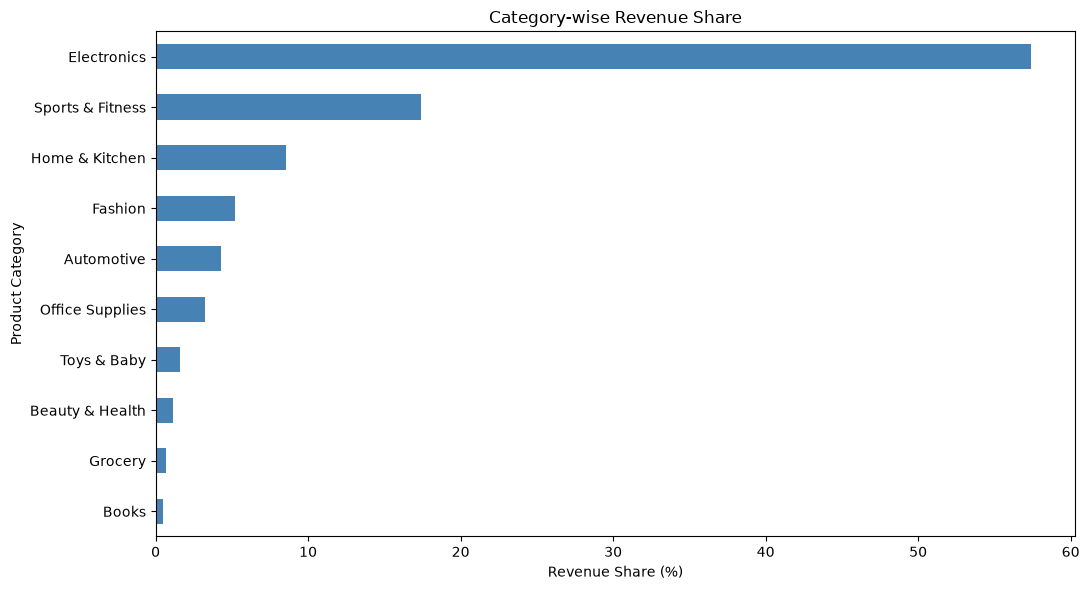

In [22]:
plt.figure(figsize=(11, 6))

category_share.sort_values().plot(kind="barh", color="steelblue")

plt.title("Category-wise Revenue Share")
plt.xlabel("Revenue Share (%)")
plt.ylabel("Product Category")
plt.tight_layout()

plt.savefig(
    chart_path / "chart_03_category-wise_revenue_share.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Observations — Category-wise Revenue Share**

1. Electronics contributes the highest share of total revenue at **57.41%**, followed by Sports & Fitness at **17.38%** and Home & Kitchen at **8.54%**.
2. Electronics alone generates more revenue than all the other categories combined, indicating a strong concentration of revenue in this category.
3. Books (0.49%), Grocery (0.65%), and Beauty & Health (1.15%) contribute the smallest revenue shares.

### NEXT: Top 10 States by Number of Orders

In [24]:
state_orders = (
    orders.groupby("state")["order_id"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

print(state_orders)

state
Uttar Pradesh     9507
Maharashtra       8179
Gujarat           3811
Madhya Pradesh    3741
Tamil Nadu        3664
Karnataka         3102
Rajasthan         3047
West Bengal       2103
Punjab            2073
Jharkhand         2044
Name: order_id, dtype: int64


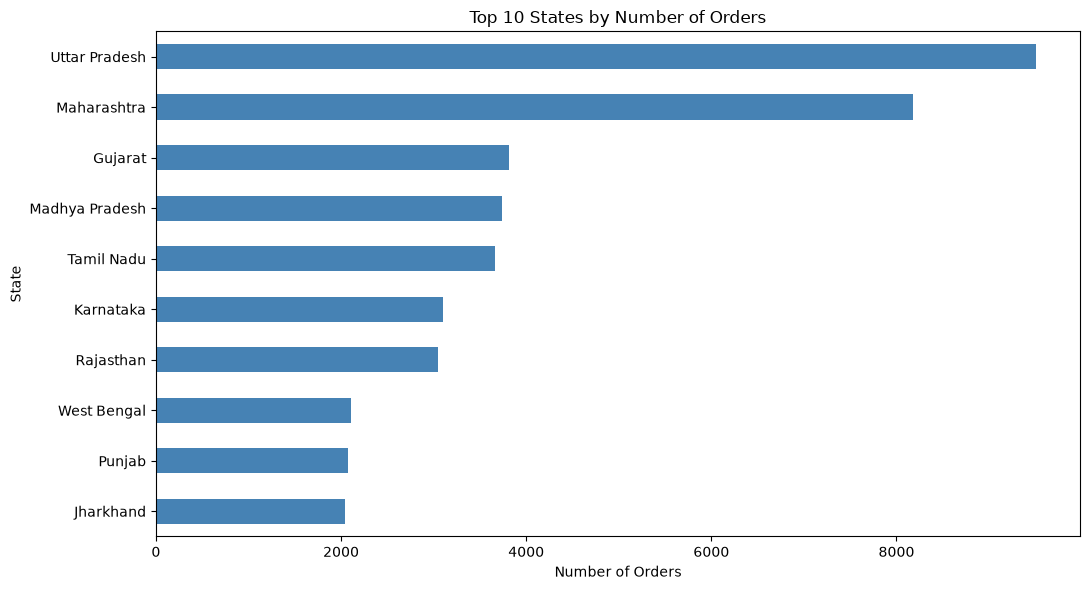

In [25]:
plt.figure(figsize=(11, 6))

state_orders.sort_values().plot(kind="barh", color="steelblue")

plt.title("Top 10 States by Number of Orders")
plt.xlabel("Number of Orders")
plt.ylabel("State")
plt.tight_layout()

plt.savefig(
    chart_path / "chart_05_top_10_states_by_orders.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Observations — Top 10 States by Number of Orders**

1. Uttar Pradesh has the highest number of orders (9,507), followed by Maharashtra (8,179). These two states lead the dataset by a considerable margin.
2. Gujarat (3,811), Madhya Pradesh (3,741), and Tamil Nadu (3,664) form the next group, with relatively similar order counts.
3. Jharkhand (2,044), Punjab (2,073), and West Bengal (2,103) have the lowest order counts among the top 10 states shown.

### NEXT: Customer Segment Distribution

In [26]:
segment_counts = customers["segment"].value_counts()

print(segment_counts)

segment
Regular     4026
Budget      2505
Premium     1501
New         1488
Inactive     480
Name: count, dtype: int64


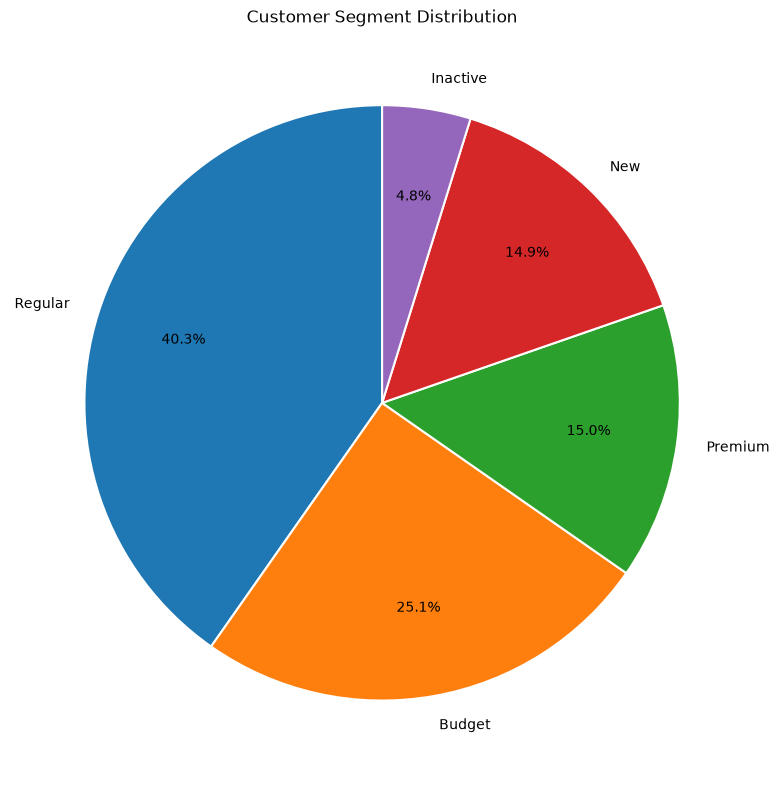

In [27]:
plt.figure(figsize=(8, 8))

plt.pie(
    segment_counts,
    labels=segment_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.7,
    wedgeprops={"edgecolor": "white", "linewidth": 1.5}
)

plt.title("Customer Segment Distribution")
plt.tight_layout()

plt.savefig(
    chart_path / "chart_06_customer_segment_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Observations — Customer Segment Distribution**

1. Regular customers form the largest segment, with **4,026 customers (40.3%)**, followed by Budget customers with **2,505 (25.1%)**.
2. Premium customers account for **1,501 customers (15.0%)**, while New customers represent 14.9% and Inactive customers represent 4.8%.
3. Although the PRD specifically mentions Premium, Regular, and Budget customers, the dataset also contains New and Inactive segments. All five have been included to represent the complete customer distribution accurately.


### NEXT: Payment Method Usage

In [28]:
payment_counts = orders["payment_method"].value_counts()

print(payment_counts)

payment_method
UPI                 17570
Credit Card         10007
Debit Card           7624
Cash on Delivery     5883
Net Banking          4026
EMI                  2943
Wallet               1947
Name: count, dtype: int64


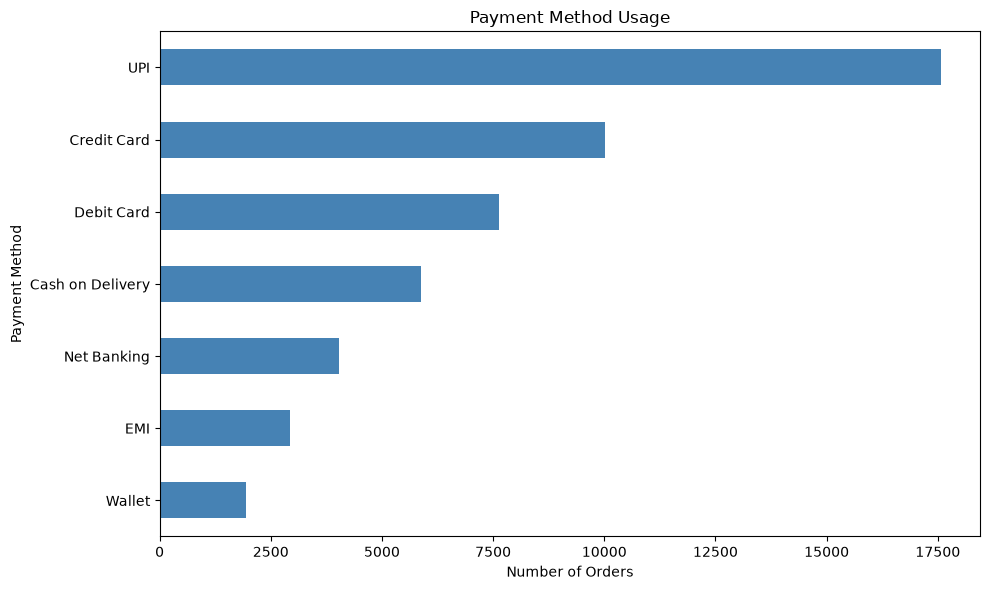

In [29]:
plt.figure(figsize=(10, 6))

payment_counts.sort_values().plot(kind="barh", color="steelblue")

plt.title("Payment Method Usage")
plt.xlabel("Number of Orders")
plt.ylabel("Payment Method")
plt.tight_layout()

plt.savefig(
    chart_path / "chart_07_payment_method_usage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Observations — Payment Method Usage**

1. UPI is the most popular payment method, used in **17,570 orders (35.14%)**, followed by Credit Card with 10,007 orders (20.01%).
2. Debit Card accounts for 7,624 orders, while Cash on Delivery accounts for 5,883 orders. Together, digital payment methods dominate the dataset.
3. Wallet is the least-used method, with 1,947 orders (3.89%), followed by EMI with 2,943 orders (5.89%).

### NEXT: Age Distribution of Customers (which age groups shop most)

In [30]:
print(customers["age"].describe())

print("\nMissing age values:", customers["age"].isna().sum())

count    10000.00000
mean        41.67630
std         13.83438
min         18.00000
25%         30.00000
50%         42.00000
75%         54.00000
max         65.00000
Name: age, dtype: float64

Missing age values: 0


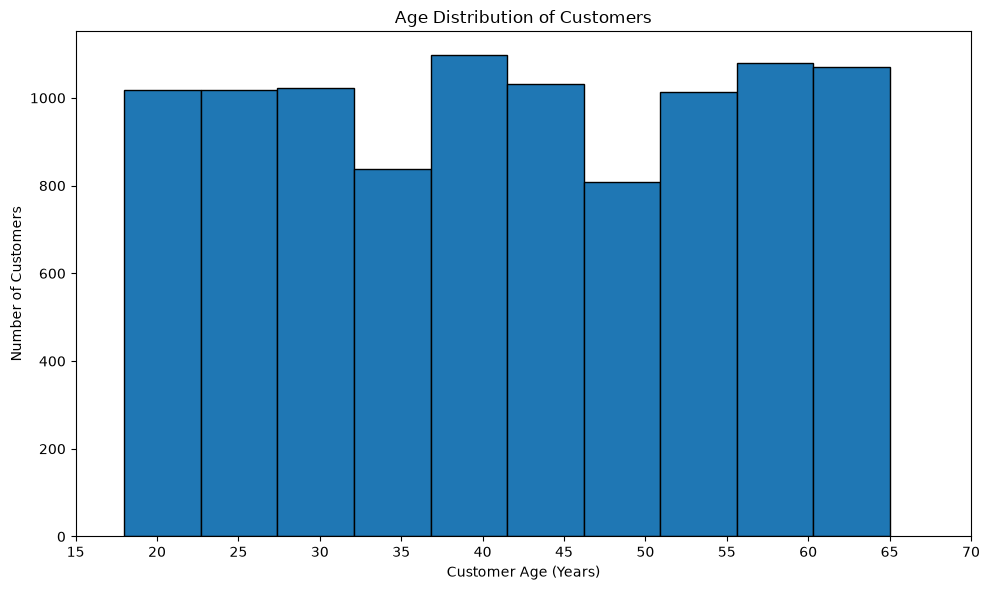

In [31]:
plt.figure(figsize=(10, 6))

plt.hist(customers["age"], bins=10, edgecolor="black")

plt.title("Age Distribution of Customers")
plt.xlabel("Customer Age (Years)")
plt.ylabel("Number of Customers")
plt.xticks(range(15, 71, 5))
plt.tight_layout()

plt.savefig(
    chart_path / "chart_08_customer_age_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Observations — Age Distribution of Customers**

1. Customer ages range from **18 to 65 years**, with an average age of 41.7 years and a median of 42 years.
2. The distribution is relatively spread across the age range, with noticeable concentrations around ages 37–42 and 56–62.
3. No single age group overwhelmingly dominates the distribution, suggesting that customers span a broad range of adult age groups.

### NEXT: Return Reasons

In [33]:
print(returns.columns.tolist())

['return_id', 'order_id', 'customer_id', 'return_date', 'reason', 'return_amount', 'refund_status', 'refund_date', 'return_condition', 'remarks']


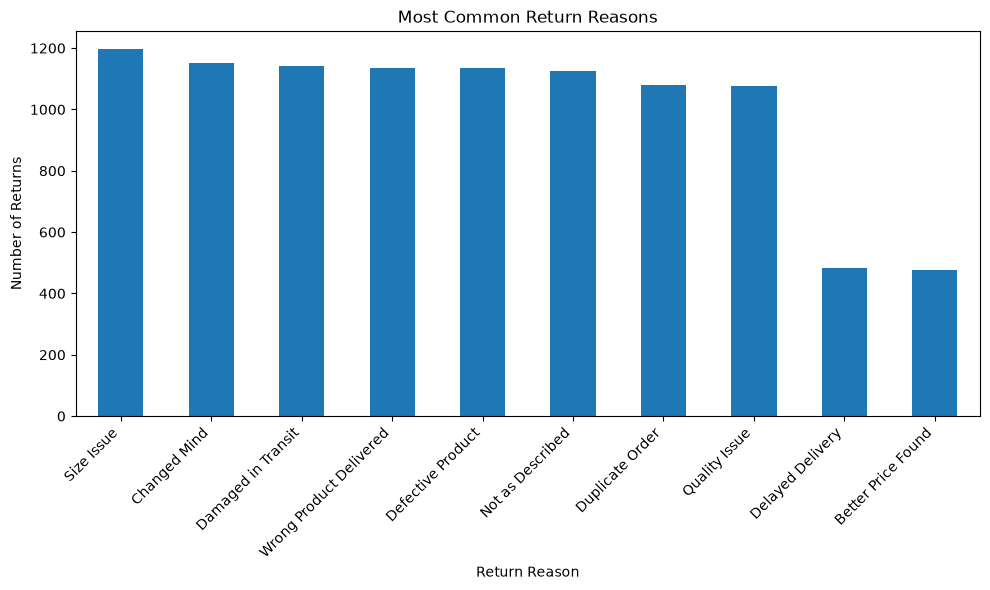

In [34]:
return_reasons = returns["reason"].value_counts()

plt.figure(figsize=(10, 6))
return_reasons.plot(kind="bar")

plt.title("Most Common Return Reasons")
plt.xlabel("Return Reason")
plt.ylabel("Number of Returns")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(chart_path / "chart_09_return_reasons.png", dpi=300, bbox_inches="tight")
plt.show()

**Observations:**
1. Size Issue is the most common return reason, with approximately 1,200 returns. Changed Mind and Damaged in Transit are the next most frequent reasons, each accounting for around 1,140 returns.
2. Delayed Delivery and Better Price Found are the least common return reasons, with fewer than 500 returns each.
3. The high number of size-related returns suggests that improving product sizing information could help reduce returns.

### NEXT: Average Order Value (AOV) by Customer Segment.

In [35]:
orders_with_segment = orders.merge(
    customers[["customer_id", "segment"]],
    on="customer_id",
    how="left"
)

aov_by_segment = orders_with_segment.groupby("segment")["final_amount"].mean().sort_values(ascending=False)

print(aov_by_segment.round(2))

segment
Budget      64124.56
New         63381.58
Regular     63123.55
Premium     61876.90
Inactive    57120.14
Name: final_amount, dtype: float64


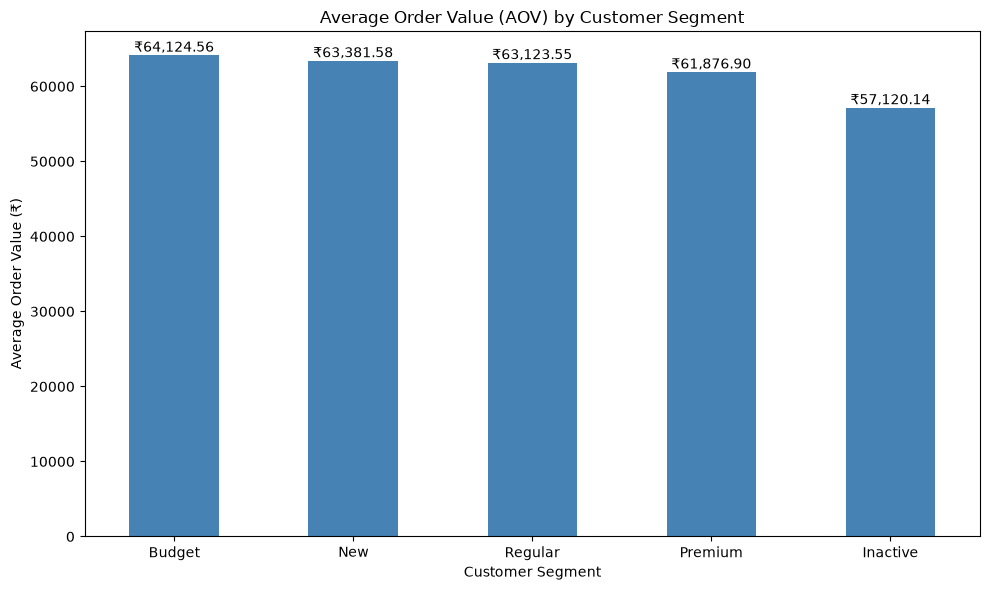

In [36]:
plt.figure(figsize=(10, 6))

aov_by_segment.plot(kind="bar", color="steelblue")

plt.title("Average Order Value (AOV) by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Order Value (₹)")
plt.xticks(rotation=0)

for i, value in enumerate(aov_by_segment):
    plt.text(i, value + 500, f"₹{value:,.2f}", ha="center")

plt.tight_layout()

plt.savefig(
    chart_path / "chart_10_aov_by_segment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Observations:**

1. Budget customers have the highest average order value (AOV) at ₹64,124.56, followed by New customers at ₹63,381.58 and Regular customers at ₹63,123.55.
2. Premium customers have an average order value of ₹61,876.90, which is lower than that of Budget, New, and Regular customers.
3. Inactive customers have the lowest AOV at ₹57,120.14, approximately ₹7,004 less than Budget customers, indicating a difference in average spending per order across segments.